In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
merged_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_merged_all_datasets_allcols.parquet'
merged = pd.read_parquet(merged_file, engine='pyarrow')

In [3]:
merged

,grid_lat,grid_lon,date,hour,h_precip_mm,datetime,no2_mean,no2_std,no2_count,no2_sem,...,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state,state_name
0,36.05,-91.15,None,None,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,AR,Arkansas
1,36.05,-91.05,None,None,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,47.916667,0.0,33.333333,0.000000,2.083333,AR,Arkansas
2,36.05,-90.95,None,None,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,1.515152,0.0,46.212121,22.727273,26.515152,AR,Arkansas
3,36.05,-90.85,None,None,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,8.333333,0.0,65.972222,2.777778,11.805556,AR,Arkansas
4,36.05,-90.75,None,None,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,1.515152,0.0,76.515152,0.000000,4.545455,AR,Arkansas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33395116,48.95,-97.25,2024-07-31,23:00:00,0.230,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,0.000000,0.0,0.000000,77.272727,22.727273,ND,North Dakota
33395117,48.95,-97.15,2024-07-31,23:00:00,0.115,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,0.000000,0.0,0.000000,36.111111,59.027778,MN,Minnesota
33395118,48.95,-97.05,2024-07-31,23:00:00,0.075,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,0.000000,0.0,0.000000,12.878788,0.757576,MN,Minnesota
33395119,48.95,-96.95,2024-07-31,23:00:00,0.025,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,...,0.0,0.0,0.000000,25.000000,0.0,0.000000,0.000000,0.000000,MN,Minnesota


In [4]:
merged.columns

Index(['grid_lat', 'grid_lon', 'date', 'hour', 'h_precip_mm', 'datetime',
       'no2_mean', 'no2_std', 'no2_count', 'no2_sem',
       'eff_cloud_fraction_mean', 'eff_cloud_fraction_std',
       'amf_cloud_fraction_mean', 'amf_cloud_fraction_std',
       'snow_ice_fraction_mean', 'snow_ice_fraction_std', 'cv_no2',
       'datetime_local', 'local_hour', 'no2_scaled_by_hour', 'rolling_mean',
       'rolling_std', 'pulse_threshold', 'above_3sd', 'prev_above', 'run_id',
       'run_len', 'pulse_start', 'sm_surface', 'surface_temp',
       'soil_temp_layer1', 'LAI', 'catchment_model_porosity', 'WFPS_c',
       'clay_percent', 'sand_percent', 'silt_percent', 'ksat', 'ph',
       'soil_om_kg_m2', 'bulk_density', 'water_storage', 'dominant_texture',
       'pct_clay', 'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
       'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
       'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam', 'state',
       'state_name

# making filtered df with only wanted columns 

In [5]:
merged['rsd'] = (merged['no2_std'] / merged['no2_mean']) * 100
merged['rsd'].describe()

count    2.589516e+06
mean     4.316361e+01
std      1.641879e+01
min      2.683266e+00
25%      3.108613e+01
50%      4.135579e+01
75%      5.315988e+01
max      2.108182e+02
Name: rsd, dtype: float64

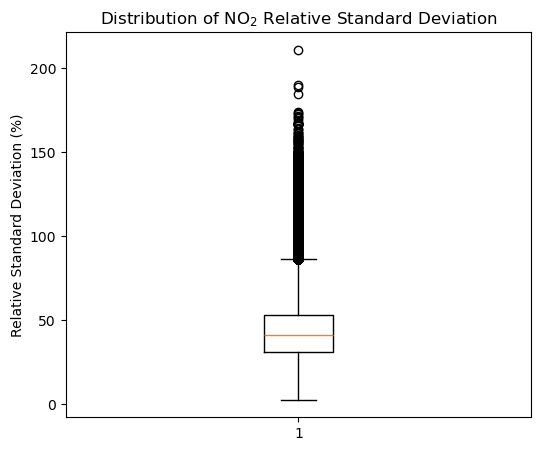

In [6]:
plt.figure(figsize=(6,5))
plt.boxplot(merged['rsd'].dropna())

plt.ylabel('Relative Standard Deviation (%)')
plt.title('Distribution of NO$_2$ Relative Standard Deviation')

plt.show()

In [7]:
merged_filtered = merged.drop(columns={'eff_cloud_fraction_mean', 'eff_cloud_fraction_std','no2_count',
       'amf_cloud_fraction_mean', 'amf_cloud_fraction_std', 'rolling_mean','date','hour',
       'rolling_std', 'pulse_threshold', 'above_3sd', 'prev_above', 'run_id','clay_percent', 'sand_percent', 'silt_percent',
       'run_len', 'LAI', 'catchment_model_porosity', 'ksat', 'ph', 'water_storage','soil_om_kg_m2', 'bulk_density', 
        'state','rsd'
                                      })

In [8]:
merged_filtered

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas
1,36.05,-91.05,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,47.916667,0.0,33.333333,0.000000,2.083333,Arkansas
2,36.05,-90.95,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,1.515152,0.0,46.212121,22.727273,26.515152,Arkansas
3,36.05,-90.85,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,8.333333,0.0,65.972222,2.777778,11.805556,Arkansas
4,36.05,-90.75,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,1.515152,0.0,76.515152,0.000000,4.545455,Arkansas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33395116,48.95,-97.25,0.230,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,77.272727,22.727273,North Dakota
33395117,48.95,-97.15,0.115,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,36.111111,59.027778,Minnesota
33395118,48.95,-97.05,0.075,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,12.878788,0.757576,Minnesota
33395119,48.95,-96.95,0.025,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,25.000000,0.0,0.000000,0.000000,0.000000,Minnesota


In [9]:
merged_filtered.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name'],
      dtype='object')

In [10]:
#saving merged dataframe
output_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_32cols_pps_smap_no2_soil_state_localtime.parquet'
merged_filtered.to_parquet(output_file, engine='pyarrow', index=False)
print(f"\nSaved to: {output_file}")


Saved to: /global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_32cols_pps_smap_no2_soil_state_localtime.parquet


# pps, smap, no2, dominant soil 

In [11]:
merged.columns

Index(['grid_lat', 'grid_lon', 'date', 'hour', 'h_precip_mm', 'datetime',
       'no2_mean', 'no2_std', 'no2_count', 'no2_sem',
       'eff_cloud_fraction_mean', 'eff_cloud_fraction_std',
       'amf_cloud_fraction_mean', 'amf_cloud_fraction_std',
       'snow_ice_fraction_mean', 'snow_ice_fraction_std', 'cv_no2',
       'datetime_local', 'local_hour', 'no2_scaled_by_hour', 'rolling_mean',
       'rolling_std', 'pulse_threshold', 'above_3sd', 'prev_above', 'run_id',
       'run_len', 'pulse_start', 'sm_surface', 'surface_temp',
       'soil_temp_layer1', 'LAI', 'catchment_model_porosity', 'WFPS_c',
       'clay_percent', 'sand_percent', 'silt_percent', 'ksat', 'ph',
       'soil_om_kg_m2', 'bulk_density', 'water_storage', 'dominant_texture',
       'pct_clay', 'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
       'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
       'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam', 'state',
       'state_name

In [12]:
merged_pps_smap_no2_domsoil = merged.drop(columns={'no2_count', 'eff_cloud_fraction_mean','snow_ice_fraction_mean',
       'snow_ice_fraction_std', 'cv_no2', 'date','hour','no2_sem', 'local_hour',
        'eff_cloud_fraction_std','amf_cloud_fraction_mean', 'amf_cloud_fraction_std', 'rolling_mean',
       'rolling_std', 'pulse_threshold', 'above_3sd', 'prev_above', 'run_id','run_len','LAI', 'catchment_model_porosity','clay_percent', 'sand_percent', 'silt_percent', 'ksat', 'ph',
       'soil_om_kg_m2', 'bulk_density', 'water_storage', 'pct_clay', 'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
       'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
       'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam','state','rsd'
                                      })

In [13]:
merged_pps_smap_no2_domsoil

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,datetime_local,no2_scaled_by_hour,pulse_start,sm_surface,surface_temp,soil_temp_layer1,WFPS_c,dominant_texture,state_name
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,2024-02-29 16:00:00,NaN,None,NaN,NaN,NaN,NaN,silt loam,Arkansas
1,36.05,-91.05,NaN,2024-02-29 22:00:00,NaN,NaN,2024-02-29 16:00:00,NaN,None,NaN,NaN,NaN,NaN,sandy loam,Arkansas
2,36.05,-90.95,NaN,2024-02-29 22:00:00,NaN,NaN,2024-02-29 16:00:00,NaN,None,NaN,NaN,NaN,NaN,silt loam,Arkansas
3,36.05,-90.85,NaN,2024-02-29 22:00:00,NaN,NaN,2024-02-29 16:00:00,NaN,None,NaN,NaN,NaN,NaN,silt loam,Arkansas
4,36.05,-90.75,NaN,2024-02-29 22:00:00,NaN,NaN,2024-02-29 16:00:00,NaN,None,NaN,NaN,NaN,NaN,silt loam,Arkansas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33395116,48.95,-97.25,0.230,2024-07-31 23:00:00,NaN,NaN,2024-07-31 18:00:00,NaN,None,NaN,NaN,NaN,NaN,silty clay,North Dakota
33395117,48.95,-97.15,0.115,2024-07-31 23:00:00,NaN,NaN,2024-07-31 18:00:00,NaN,None,NaN,NaN,NaN,NaN,silty clay loam,Minnesota
33395118,48.95,-97.05,0.075,2024-07-31 23:00:00,NaN,NaN,2024-07-31 18:00:00,NaN,None,NaN,NaN,NaN,NaN,clay,Minnesota
33395119,48.95,-96.95,0.025,2024-07-31 23:00:00,NaN,NaN,2024-07-31 18:00:00,NaN,None,NaN,NaN,NaN,NaN,clay,Minnesota


In [14]:
merged_pps_smap_no2_domsoil.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'datetime_local', 'no2_scaled_by_hour', 'pulse_start',
       'sm_surface', 'surface_temp', 'soil_temp_layer1', 'WFPS_c',
       'dominant_texture', 'state_name'],
      dtype='object')

In [15]:
#saving merged dataframe
output_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_pps_smap_no2_domsoil_15cols.parquet'
merged_pps_smap_no2_domsoil.to_parquet(output_file, engine='pyarrow', index=False)
print(f"\nSaved to: {output_file}")


Saved to: /global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_pps_smap_no2_domsoil_15cols.parquet
